# Descriptive analysis of Digikala reviews

This notebook is the data audit of the project. Before any model is trained, it answers three questions:

1. Was the data read completely and correctly?
2. What is wrong with it, and what was done about each problem?
3. What does the data look like, and what does that mean for the modeling choices?

All counts are computed on the **full dataset** (6,156,289 reviews). If a plot or example uses a sample,
the cell says so and gives the seed.

The heavy lifting lives in `src/digikala_reviews/` and `scripts/`. This notebook loads their outputs,
runs a few extra checks with pandas, and explains the results.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from digikala_reviews import plotting
from digikala_reviews.config import (
    COMMENTS_CLEAN_PARQUET,
    COMMENTS_RAW_DIR,
    EXCLUDED_ROWS_PARQUET,
    REPORTS_DIR,
)
from digikala_reviews.quality import is_missing

plotting.apply_style()
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", "{:,.2f}".format)


def load_report(name):
    return json.loads((REPORTS_DIR / name).read_text(encoding="utf-8"))


ingest = load_report("data_ingest.json")
gate = load_report("quality_gate.json")
cleaning = load_report("cleaning_report.json")

## 1. Reading the data

The dataset is the public [Digikala comments and products](https://huggingface.co/datasets/RadeAI/Digikala_comments_products)
dump on Hugging Face: one CSV of reviews and one CSV of products.

`scripts/build_parquet.py` converts both files to Parquet with pandas. Every column is read as **text** and
pandas' automatic missing-value detection is turned off, so nothing is converted or dropped silently at this
point; type checks happen in the quality gate. Review bodies can contain line breaks, so records are counted
with a real CSV parser, not by counting lines. To be sure nothing was lost, the records are counted twice, with
pandas and with Python's own `csv` module, and the SHA-256 of each file is recorded so anyone can check they have
exactly the same data.

In [2]:
pd.DataFrame(
    [
        {
            "file": f["csv_file"],
            "rows (pandas)": f["rows_pandas"],
            "rows (csv module)": f["rows_csv_module"],
            "CSV (MB)": round(f["csv_size_bytes"] / 1e6),
            "Parquet (MB)": round(f["parquet_size_bytes"] / 1e6),
            "sha256": f["csv_sha256"][:16] + "...",
        }
        for f in ingest["files"]
    ]
).set_index("file")

,rows (pandas),rows (csv module),CSV (MB),Parquet (MB),sha256
file,,,,,
digikala-comments.csv,6156289,6156289,1279,451,c7a8aa3020334fde...
digikala-products.csv,1283496,1283496,259,47,0f646e1b0ba5a075...


Both counts agree: **6,156,289 reviews** and **1,283,496 product rows**, and pandas raised no parsing error.
The project brief mentions "about 7 million" reviews; the real number is 6.16 million.
The Parquet copy is about 4x smaller than the CSV and much faster to query, so everything below reads from it.

## 2. Quality gate

`scripts/run_quality_gate.py` checks the schema, missing values, numeric columns, label vocabulary, dates and
duplicates. It does not change anything: it only counts problems and keeps examples.

One thing showed up immediately: in this CSV, missing values are written as the literal text `nan`
(the file was exported with pandas). So throughout the project a value counts as **missing** when it is blank,
contains only whitespace or invisible characters, or equals `nan`.

### 2.1 Schema

In [3]:
schema = gate["comments"]["schema"]
print("Columns:", ", ".join(schema["columns"]))
print("Missing expected columns:", schema["missing_expected"] or "none")
print("Unexpected columns:", schema["unexpected"] or "none")

Columns: id, title, body, created_at, rate, recommendation_status, is_buyer, product_id, advantages, disadvantages, likes, dislikes, seller_title, seller_code, true_to_size_rate
Missing expected columns: none
Unexpected columns: none


All 15 expected columns are present. Only `body` is used as model input. `rate` and `recommendation_status`
are targets, and `product_id` is used only to split the data by product. The rest is kept for the audit.

### 2.2 Missing values

In [4]:
missing = pd.DataFrame(gate["comments"]["missing_values"]).T[["blank", "nan_token", "missing", "missing_pct"]]
missing = missing.sort_values("missing_pct", ascending=False)
missing

,blank,nan_token,missing,missing_pct
true_to_size_rate,0.00,"6,065,516.00","6,065,516.00",98.53
disadvantages,0.00,"5,744,017.00","5,744,017.00",93.30
advantages,0.00,"5,448,084.00","5,448,084.00",88.50
title,"3,241.00","2,865,062.00","2,868,303.00",46.59
recommendation_status,0.00,"894,426.00","894,426.00",14.53
seller_title,0.00,"302,181.00","302,181.00",4.91
seller_code,0.00,"302,181.00","302,181.00",4.91
body,208.00,637.00,845.00,0.01
rate,0.00,0.00,0.00,0.00
created_at,0.00,0.00,0.00,0.00


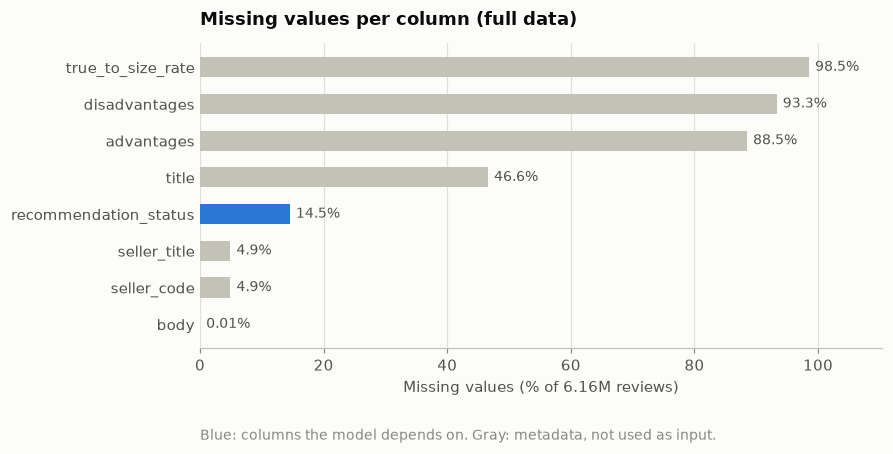

In [5]:
model_columns = {"body", "rate", "recommendation_status", "product_id"}
shown = missing[missing["missing_pct"] > 0]

fig, ax = plt.subplots(figsize=(8, 3.6))
plotting.hbar(
    ax,
    labels=list(shown.index),
    values=list(shown["missing_pct"]),
    colors=[plotting.SERIES[0] if c in model_columns else plotting.NEUTRAL for c in shown.index],
    value_labels=[f"{p:.2f}%" if p < 1 else f"{p:.1f}%" for p in shown["missing_pct"]],
    xlabel="Missing values (% of 6.16M reviews)",
)
ax.set_title("Missing values per column (full data)")
ax.text(
    0,
    -0.3,
    "Blue: columns the model depends on. Gray: metadata, not used as input.",
    transform=ax.transAxes,
    color=plotting.MUTED,
    fontsize=9,
)
plotting.save(fig, "missing_values")
plt.show()

- `body`, the only model input, is missing in just **845** reviews (0.01%): 637 are `nan` and 208 contain only
  whitespace or invisible characters. pandas would not flag those 208 as missing.
- `recommendation_status` is missing in **14.5%** of reviews (894,426). These are naturally unlabeled reviews,
  not errors. They still have a rating, so they stay useful for the rating-band task.
- `rate` and `product_id` are never missing.
- `title`, `advantages`, `disadvantages` and `true_to_size_rate` are largely empty, but none of them may be used
  as features, so this does not affect the models.

### 2.3 Is the missing seller information random?

`seller_title` and `seller_code` are missing in exactly 302,181 reviews, which is also the number of reviews
written by non-buyers. A quick cross-tab checks whether the two are the same rows.

In [6]:
sellers = pd.read_parquet(COMMENTS_RAW_DIR, columns=["is_buyer", "seller_code"])
pd.crosstab(sellers["is_buyer"], is_missing(sellers["seller_code"]).rename("seller missing"), margins=True)

seller missing,False,True,All
is_buyer,,,
False,0,302181,302181
True,5854108,0,5854108
All,5854108,302181,6156289


Every non-buyer review has no seller, and every buyer review has one. The missing seller is **structural**
(no purchase, so no seller), not random. The same question for missing recommendation labels is analyzed
in section 4.

### 2.4 Labels, ratings and dates

In [7]:
labels = pd.Series(gate["comments"]["recommendation_status"]["observed"], name="reviews").to_frame()
labels["pct"] = 100 * labels["reviews"] / labels["reviews"].sum()
labels

,reviews,pct
recommended,4162839,67.62
nan,894426,14.53
no_idea,594121,9.65
not_recommended,504903,8.20


The recommendation column uses exactly the three canonical classes plus `nan`. There are no Persian labels,
alternative spellings or extra categories, so the label mapping is the identity.

In [8]:
rate = gate["comments"]["rate"]
pd.Series(
    {
        "not a number": rate["not_a_number"],
        "inside [0, 5]": rate["in_range"],
        "outside [0, 5]": rate["out_of_range"],
        "exactly 0": rate["zero"],
        "fractional (e.g. 4.5)": rate["fractional"],
        "distinct values": rate["distinct_values"],
    },
    name="reviews",
).to_frame()

,reviews
not a number,0
"inside [0, 5]",6156288
"outside [0, 5]",1
exactly 0,529098
fractional (e.g. 4.5),228128
distinct values,177


In [9]:
pd.DataFrame(rate["out_of_range_examples"])

,src_row,id,product_id,rate,recommendation_status,body
0,4369260,38631814,5095301,2500.0,recommended,کوچک و با کیفیت


Every rating is a valid number. Only **one** falls outside 0 to 5: a rating of 2500 on a short positive review.
It could be a typo for 2.5, but guessing would be inventing data, so it is marked invalid for the rating-band
task and kept for the recommendation task.

Two numbers need a closer look later: **529,098 ratings of exactly 0** and **228,128 fractional ratings**.
Both are analyzed in section 4, because they directly affect how the `low` band should be defined.

In [10]:
dates = gate["comments"]["created_at"]
print("Rows not matching 'day month year':", dates["not_matching_format"])
print("Unknown month names:", dates["unknown_month"])
pd.Series(dates["rows_per_year"], name="reviews").to_frame().T

Rows not matching 'day month year': 0
Unknown month names: 0


,1395,1396,1397,1398,1399,1400,1401,1402
reviews,3575,6357,16693,138645,684321,1253484,2165894,1887320


Dates are Persian (Jalali) text such as `23 شهریور 1402`. All 6.16M dates have a valid format and month name,
and they span the years **1395 to 1402** (roughly 2016 to early 2024). Most reviews were written in 1400 to 1402.

### 2.5 Duplicate ids

In [11]:
dup = gate["comments"]["duplicate_ids"]
pd.Series(
    {
        "ids that appear more than once": dup["duplicated_ids"],
        "extra rows": dup["extra_rows"],
        "groups: all copies identical": dup["groups_fully_identical"],
        "groups: only metadata differs (likes, seller, ...)": dup["groups_metadata_only"],
        "groups: body, rating or label differs": dup["groups_content_differs"],
    },
    name="count",
).to_frame()

,count
ids that appear more than once,3226
extra rows,3229
groups: all copies identical,1318
"groups: only metadata differs (likes, seller, ...)",1663
"groups: body, rating or label differs",245


In [12]:
pd.DataFrame(dup["content_conflict_examples"])

,src_row,id,product_id,rate,recommendation_status,likes,body
0,3561860,12862914,2670905,5.0,recommended,0,کرم خوبیه\r\nپیشنهاد میکنم
1,3996799,12862914,2670905,0.0,recommended,0,کرم خوبیه\r\nپیشنهاد میکنم
2,2831183,17111330,2952419,0.0,not_recommended,4,حتی تو تخفیف هم ارزش خریدن نداره
3,2868980,17111330,2952419,1.0,not_recommended,4,حتی تو تخفیف هم ارزش خریدن نداره
4,3715097,22662971,853680,5.0,recommended,0,خوب بودخرید رو توصیه میکنم
5,3965442,22662971,853680,0.0,recommended,0,خوب بود
6,304459,24446421,2602504,4.0,recommended,0,خیلی جذب خوبی داره.و راحته
7,3835164,24446421,2602504,4.0,recommended,0,خیلی جذب خوبی داره.و راحته.حساسیت زا هم نیستن.


3,226 ids appear more than once. Most groups are harmless: either the copies are identical, or only counters
like `likes` differ, which suggests the data was scraped more than once. But **245 groups disagree on the
content itself**. In the examples above, the same review text has a rating of 5 in one copy and 0 in the other,
while the label stays `recommended`. That is a first hint that a rating of 0 may mean "no rating recorded"
rather than a bad rating.

A side note: an earlier exploratory count found 2,679 duplicated ids. That script read the file in chunks and only
compared each chunk against previous ones, so duplicates within the same chunk were missed. The extra-row count
(3,229) matches the number of unique ids found there, which confirms the corrected figure.

Comparing copies after stripping whitespace matters: one id has two copies that differ only by a trailing line break, with the same rating and label. Those copies count as the same review, not as a conflict.

### 2.6 Products file

In [13]:
products = gate["products"]
pd.Series(
    {
        "product rows": products["rows"],
        "distinct product ids": products["distinct_ids"],
        "ids with more than one row": products["ids_with_several_rows"],
        "ids with conflicting categories": products["ids_with_conflicting_category"],
        "products that have reviews": products["reviewed_products"],
        "reviewed products missing from the file": products["reviewed_products_missing_from_file"],
    },
    name="count",
).to_frame()

,count
product rows,1283496
distinct product ids,948352
ids with more than one row,258718
ids with conflicting categories,757
products that have reviews,331599
reviewed products missing from the file,0


The products file has repeated rows (up to 11 per id), but every reviewed product is in it. It is only used to
attach a category to each product for later error analysis, never as a model feature. When a product has
several rows, the most frequent category is used, and the 757 products with conflicting categories are marked
as ambiguous.

## 3. Cleaning

`scripts/build_clean.py` applies the rules below and writes `data/interim/comments_clean.parquet`.
The review text is copied unchanged; normalization is done later, in one shared function.

| Rule | Problem | Decision | Why |
|---|---|---|---|
| P1 | How missing values look | blank, whitespace only, or `nan` | Evidence from the quality gate |
| P2 | Empty review body (845) | Excluded from all tasks | The text is the only input |
| P3 | Missing recommendation label | Kept; used for rating band only | Required by the protocol |
| P4 | Rating outside 0 to 5 (1) | Rating band left empty; row kept | No silent correction |
| P5 | Identical copies of an id | Keep the first copy | No information lost |
| P6 | Copies differing only in metadata | Keep the first copy | Metadata is not used |
| P7 | Copies disagreeing on text, rating or label | Exclude all copies | The true label is unknown |

Every excluded row is saved with its reason in `data/interim/excluded_rows.parquet`.

In [14]:
steps = pd.Series({"raw rows": cleaning["rows_raw"]})
for reason, n in cleaning["rows_excluded"].items():
    steps[f"excluded: {reason}"] = -n
steps["clean rows"] = cleaning["rows_clean"]
steps.to_frame("rows")

,rows
raw rows,6156289
excluded: duplicate_id_extra_copy,-2984
excluded: missing_body,-845
excluded: duplicate_id_conflict,-490
clean rows,6151970


In [15]:
# The first two excluded rows for each reason
excluded = pd.read_parquet(EXCLUDED_ROWS_PARQUET)
excluded.groupby("exclusion_reason").head(2).sort_values("exclusion_reason")

,src_row,id,exclusion_reason
2,9764,52238912,duplicate_id_conflict
4,14206,53498321,duplicate_id_conflict
23,91337,6474081,duplicate_id_extra_copy
29,104126,54460135,duplicate_id_extra_copy
0,6148,20431507,missing_body
1,8758,45984959,missing_body


After cleaning, **6,151,970 reviews** remain, each id exactly once (the script checks this and stops if any
duplicate is left).

Every rating of exactly 0 is flagged with `rate_is_zero`. Section 4 shows that a 0 means "no rating recorded",
so for the rating-band task these reviews get no band (`RATE_ZERO_POLICY = "invalid"` in `config.py`).
They stay in the data for the recommendation task. The table shows the resulting bands.

In [16]:
clean = pd.read_parquet(COMMENTS_CLEAN_PARQUET, columns=["rating_band", "rate_is_zero"])
clean["rating_band"] = clean["rating_band"].fillna("no band")

bands = clean.groupby("rating_band")["rate_is_zero"].agg(reviews="size", zero_ratings="sum")
bands["pct_of_reviews"] = 100 * bands["reviews"] / bands["reviews"].sum()
bands.loc[["low", "medium", "high", "no band"]]

,reviews,zero_ratings,pct_of_reviews
rating_band,,,
low,562713,0,9.15
medium,1058360,0,17.20
high,4001982,0,65.05
no band,528915,528914,8.60


Under the protocol bands as written, the 528,914 zeros would have been `low`: almost **half of that band**.
After the decision in section 4 they have no band instead, and `low` keeps the 562,713 reviews with a real
rating below 2.5.

## 4. Three questions before defining the targets

Section 2 left three open questions that affect how the targets are built:

1. What does a rating of **0** mean: a very bad rating, or no rating at all?
2. Where do the **fractional ratings** (4.25, 3.8, ...) come from?
3. Are **missing recommendation labels** random, or do they follow a pattern?

Each question is checked from several independent angles. All tables use the full cleaned data
(6,151,970 reviews) unless a cell says otherwise.

In [17]:
import numpy as np

from digikala_reviews.dates import parse_jalali

reviews = pd.read_parquet(
    COMMENTS_CLEAN_PARQUET,
    columns=["product_id", "rate", "recommendation", "is_buyer", "created_at_jalali"],
)
reviews = reviews[reviews["rate"] <= 5].copy()  # drop the single rating of 2500
reviews["recommendation"] = reviews["recommendation"].fillna("missing")
reviews[["year", "month"]] = parse_jalali(reviews["created_at_jalali"])

# Whole ratings keep their value as a label; everything else is "fractional"
whole = reviews["rate"] % 1 == 0
reviews["rate_group"] = "fractional"
reviews.loc[whole, "rate_group"] = reviews.loc[whole, "rate"].astype(int).astype(str)

RATE_GROUPS = ["0", "1", "2", "3", "4", "5", "fractional"]
LABELS = ["recommended", "no_idea", "not_recommended", "missing"]
reviews["rate_group"].value_counts().loc[RATE_GROUPS].to_frame("reviews")

,reviews
rate_group,
0,528914
1,327322
2,197917
3,958144
4,1514685
5,2396960
fractional,228027


### 4.1 Rating vs recommendation label

If 0 meant "very bad", reviews rated 0 should look like reviews rated 1: mostly `not_recommended`.

In [18]:
by_rate = pd.crosstab(reviews["rate_group"], reviews["recommendation"], normalize="index") * 100
by_rate = by_rate.loc[RATE_GROUPS, LABELS]
by_rate

recommendation,recommended,no_idea,not_recommended,missing
rate_group,,,,
0,80.47,3.89,10.85,4.79
1,3.71,6.50,77.32,12.48
2,9.84,27.58,47.17,15.42
3,44.73,38.19,6.32,10.75
4,78.41,5.52,0.39,15.67
5,81.00,0.61,0.26,18.12
fractional,63.60,14.42,12.17,9.81


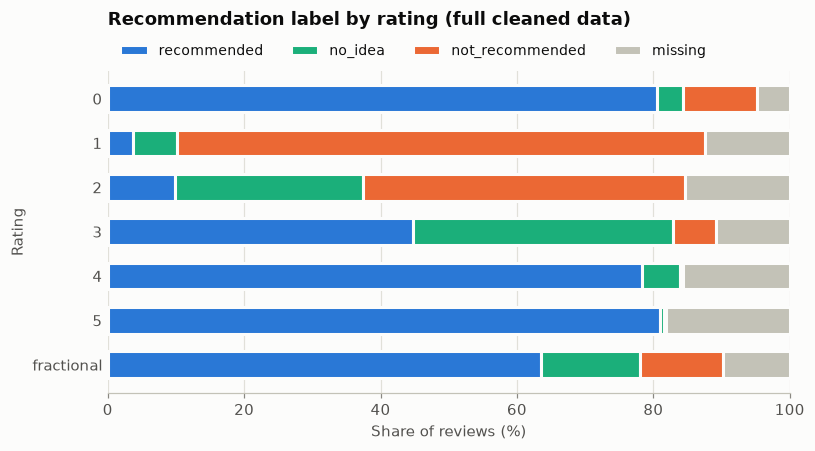

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.8))
plotting.stacked_hbar(ax, by_rate, plotting.RECOMMENDATION_COLORS)
ax.set_title("Recommendation label by rating (full cleaned data)", pad=30)
ax.set_ylabel("Rating")
plotting.save(fig, "label_by_rating")
plt.show()

### 4.2 Zero and fractional ratings over time

If zeros were ordinary bad ratings, their share should be roughly stable over time.
A sudden change points to a change in how the site recorded ratings.

In [20]:
monthly = reviews.groupby(["year", "month"]).agg(
    reviews=("rate", "size"),
    zero_pct=("rate", lambda r: 100 * (r == 0).mean()),
    fractional_pct=("rate_group", lambda g: 100 * (g == "fractional").mean()),
)
monthly = monthly[monthly["reviews"] >= 1000]  # very small months give noisy shares
monthly.index = [f"{y}-{m:02d}" for y, m in monthly.index]
monthly.head(3)

,reviews,zero_pct,fractional_pct
1397-03,1039,4.72,50.43
1397-05,1066,2.53,46.06
1397-06,1034,2.80,46.03


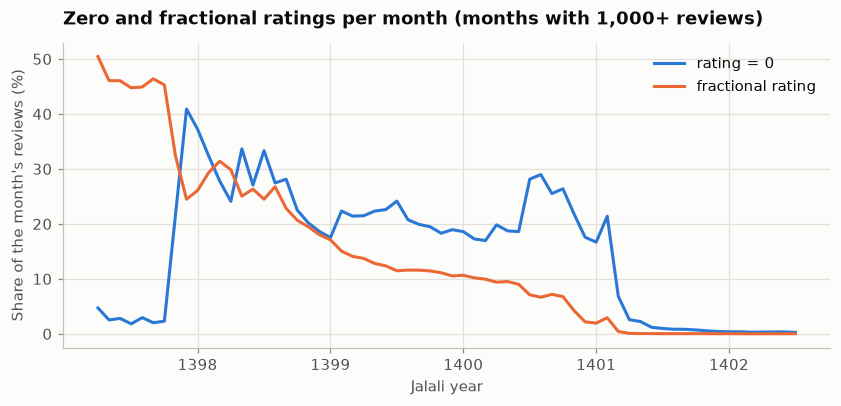

In [21]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x = range(len(monthly))
ax.plot(x, monthly["zero_pct"], color=plotting.SERIES[0], label="rating = 0")
ax.plot(x, monthly["fractional_pct"], color=plotting.SERIES[1], label="fractional rating")

year_starts = [i for i, label in enumerate(monthly.index) if label.endswith("-01")]
ax.set_xticks(year_starts, [monthly.index[i][:4] for i in year_starts])
ax.set_ylabel("Share of the month's reviews (%)")
ax.set_xlabel("Jalali year")
ax.legend(loc="upper right")
ax.set_title("Zero and fractional ratings per month (months with 1,000+ reviews)")
plotting.save(fig, "zero_fractional_over_time")
plt.show()

### 4.3 Buyers vs non-buyers

In [22]:
buyer_zero = reviews.groupby("is_buyer")["rate"].agg(
    reviews="size",
    zero_pct=lambda r: 100 * (r == 0).mean(),
)
buyer_zero

,reviews,zero_pct
is_buyer,,
False,301906,4.77
True,5850063,8.79


### 4.4 What do the texts say?

A rough signal from the words people use. The check counts reviews that contain a clearly positive
word (`عالی`, "excellent") or a clearly negative one (`افتضاح`, `ناراضی`, `پشیمون`, `بی کیفیت`, ...).
Short or ambiguous words like `خوب` or `بد` are left out on purpose: `بد` also appears inside `بدون` ("without").

This needs the review text, so it uses a **random sample of 300,000 reviews** (seed 2026).

In [23]:
texts = pd.read_parquet(COMMENTS_CLEAN_PARQUET, columns=["body", "rate"])
texts = texts[texts["rate"] <= 5].sample(300_000, random_state=2026)
texts["rate_group"] = reviews.loc[texts.index, "rate_group"]

POSITIVE = "عالی"
NEGATIVE = "افتضاح|ناراضی|پشیمون|پشیمان|بی کیفیت|بیکیفیت|بی\u200cکیفیت"
texts["positive"] = texts["body"].str.contains(POSITIVE)
texts["negative"] = texts["body"].str.contains(NEGATIVE)

words = texts.groupby("rate_group")[["positive", "negative"]].mean() * 100
words.columns = ["has positive word (%)", "has negative word (%)"]
words.loc[RATE_GROUPS]

,has positive word (%),has negative word (%)
rate_group,,
0,16.58,1.39
1,1.27,12.60
2,2.38,5.08
3,5.24,0.88
4,9.75,0.26
5,32.91,0.36
fractional,13.95,2.38


### 4.5 Reading examples

Fifteen random reviews rated 0 from the text sample (seed 2026), with their recommendation label.

In [24]:
# Taken from the 300,000-review text sample above
zero_examples = texts[texts["rate"] == 0].sample(15, random_state=2026)
zero_examples = zero_examples.join(reviews[["recommendation", "is_buyer", "created_at_jalali"]])
zero_examples["body"] = zero_examples["body"].str[:150]
zero_examples[["recommendation", "is_buyer", "created_at_jalali", "body"]]

,recommendation,is_buyer,created_at_jalali,body
3346640,recommended,True,8 شهریور 1400,فیلتر خوبی ب نظر میرسه ببینیم چقدر کار میکنه من بدون تفلن بستم همراهش ی واشر...
2384147,recommended,True,27 مهر 1400,کتاب بسیار خواندنی
3993965,recommended,True,26 فروردین 1399,قبلاً برندهای زیادی بودن که دستمال آرایش پاک کن پوست حساس و خشک داشتن اما ال...
4906585,recommended,True,21 تیر 1400,خیلی خوب و بموقع به دستم رسید
883051,recommended,True,15 آذر 1400,اولین کتاب از چهارگانه جان فانته
1887332,recommended,True,11 مهر 1400,خیلی خوبه . انواع لباس های نازک دوز رو داره
373273,missing,True,12 اردیبهشت 1401,فوق العاده
679252,recommended,True,9 مهر 1401,من استفاده کردم راضیم.البته برای هر مویی شاید خوب نباشد
5863612,recommended,True,25 تیر 1400,خوبه دیگه برای تقویت استدلال
3055109,recommended,True,16 اسفند 1400,من چون تعریفش رو شنیده بودم خریدم\r\nحالت رومانی داره


### 4.6 Fractional ratings

Which fractional values occur? Steps of 0.25 (4.25, 3.75) suggest an average of four sub-scores,
steps of 0.2 (4.2, 3.8) an average of five.

In [25]:
fractional = reviews.loc[reviews["rate_group"] == "fractional", "rate"]
step = np.select(
    [np.isclose((fractional * 4) % 1, 0), np.isclose((fractional * 5) % 1, 0)],
    ["multiple of 0.25", "multiple of 0.2"],
    default="other",
)
print(pd.Series(step).value_counts())
fractional.value_counts().head(10).to_frame("reviews")

multiple of 0.25    85696
multiple of 0.2     85420
other               56911
Name: count, dtype: int64


,reviews
rate,
4.50,13471
3.50,12205
4.25,11650
3.75,10044
4.20,9840
3.80,8739
4.40,8673
4.75,8287
4.60,8150


### 4.7 Are missing recommendation labels random?

The share of reviews without a label, split by buyer status, rating, product popularity and year.
If the label were missing at random, all these shares would be close to the overall 14.5%.

In [26]:
reviews["label_missing"] = reviews["recommendation"] == "missing"

reviews_per_product = reviews.groupby("product_id")["rate"].transform("size")
reviews["product_popularity"] = pd.cut(
    reviews_per_product,
    bins=[0, 1, 10, 100, 1000, np.inf],
    labels=["1 review", "2-10", "11-100", "101-1000", "1000+"],
)

for column in ["is_buyer", "rate_group", "product_popularity", "year"]:
    share = reviews.groupby(column, observed=True)["label_missing"].agg(reviews="size", missing_pct="mean")
    share["missing_pct"] *= 100
    print(f"\n{column}")
    print(share.to_string())


is_buyer
          reviews  missing_pct
is_buyer                      
False      301906       100.00
True      5850063        10.12

rate_group
            reviews  missing_pct
rate_group                      
0            528914         4.79
1            327322        12.48
2            197917        15.42
3            958144        10.75
4           1514685        15.67
5           2396960        18.12
fractional   228027         9.81

product_popularity
                    reviews  missing_pct
product_popularity                      
1 review              91982        20.31
2-10                 634902        18.43
11-100              2330730        15.41
101-1000            3094355        12.89

year
      reviews  missing_pct
year                      
1395     3561        97.11
1396     6341        97.40
1397    16660        48.02
1398   138525        13.45
1399   684132         5.63
1400  1253096         4.78
1401  2164887        26.28
1402  1884767        10.10


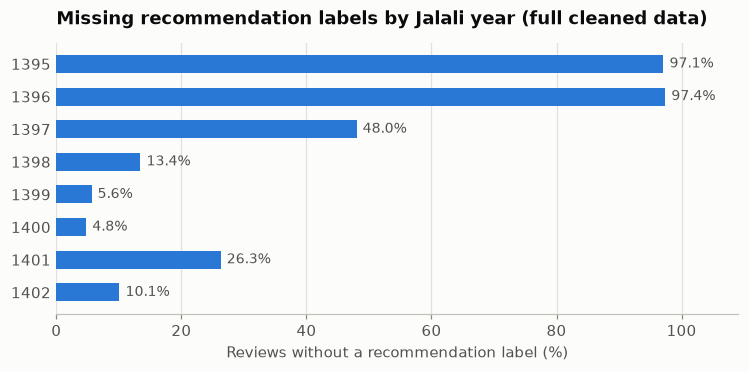

In [27]:
by_year = reviews.groupby("year")["label_missing"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 3.2))
plotting.hbar(
    ax,
    labels=[str(y) for y in by_year.index],
    values=list(by_year),
    value_labels=[f"{v:.1f}%" for v in by_year],
    xlabel="Reviews without a recommendation label (%)",
)
ax.set_title("Missing recommendation labels by Jalali year (full cleaned data)")
plotting.save(fig, "missing_labels_by_year")
plt.show()

### 4.8 Findings

**A rating of 0 means "no rating recorded", not "very bad".** Six independent checks point the same way:

- 80% of zero-rated reviews are `recommended`, just like ratings of 4 and 5, while reviews rated 1 are
  77% `not_recommended`.
- Zeros appear suddenly in late 1397, stay at 20-40% of each month's reviews until 1400, and vanish in early 1401.
  Real bad ratings would not switch on and off like that; it looks like a change in how the site stored ratings.
- Zero-rated texts use the positive word about as often as 4-5 star reviews, and negative words rarely
  (1.4%, against 12.6% for a rating of 1).
- 14 of the 15 random zero-rated reviews above are clearly positive.
- Some duplicated reviews have a 5 in one copy and a 0 in the other (section 2.5).
- The dataset card on Hugging Face does not document the columns, so the decision rests on this evidence.

About 11% of zeros are `not_recommended`, so a few may be genuinely bad, but without a recorded rating there is
no way to tell them apart.

**Decision:** for the rating-band task, a rating of 0 is treated as missing (`RATE_ZERO_POLICY = "invalid"`).
These reviews stay in the data and are still used for the recommendation task. The `low` band shrinks from
1.09M to 0.56M reviews, but it loses about half of its wrong labels. The effect of this choice is measured again
with the baseline models, where both rules are compared side by side.

**Fractional ratings are real ratings from an older rating system.** Most are multiples of 0.25 or 0.2, which fits
an average of several sub-scores. They make up about half of the reviews in 1397 and fade out by 1401. They lie
inside [0, 5], so the bands apply to them unchanged. Values close to a band edge (for example 3.8, which is
`medium`) are worth a look in the error analysis.

**Missing recommendation labels are structural, not random.**

- Every review written by a non-buyer (301,906) has no label; only 10% of buyer reviews lack one.
- 97% of the reviews from 1395-1396 have no label, about 5% in 1399-1400, and 26% in 1401.
- Reviews of less popular products miss the label more often (20% against 13%).

So naturally unlabeled reviews are older, more often written by non-buyers, and more often about niche products.
They are not a random sample of the labeled data. This is why the main semi-supervised experiment uses the
protocol's random mask, and the naturally unlabeled reviews are only an optional extension.

**Side note:** no product has more than 1,000 reviews. Section 5.1 looks at this more closely: the real limit is
much lower, around 200 reviews per product.

## 5. Descriptive statistics

This section completes the descriptive analysis required by the project brief (A1 to A5). Parts of it were
already covered above (row counts, missing values, duplicate ids); here the remaining pieces are added.

Everything uses the **full cleaned data**. To keep memory low, the dataframes from section 4 are released first.

In [28]:
del reviews, texts, clean  # free memory before loading the review texts
data = pd.read_parquet(COMMENTS_CLEAN_PARQUET)
data.dtypes.to_frame("dtype")

,dtype
src_row,int64
id,int64
product_id,int64
body,str
rate,float64
rate_is_zero,bool
rating_band,str
recommendation,str
is_buyer,bool
created_at_jalali,str


### 5.1 Size and structure (A1)

In [29]:
raw = pd.read_parquet(COMMENTS_RAW_DIR, columns=["id", "product_id", "seller_code"])
known_sellers = raw.loc[~is_missing(raw["seller_code"]), "seller_code"]
raw_per_product = raw["product_id"].value_counts()
most_reviewed = raw_per_product.index[0]

pd.Series(
    {
        "reviews in the CSV": gate["comments"]["rows"],
        "reviews after cleaning": cleaning["rows_clean"],
        "columns": len(gate["comments"]["schema"]["columns"]),
        "CSV size (GB)": round(ingest["files"][0]["csv_size_bytes"] / 1e9, 2),
        "distinct products": raw["product_id"].nunique(),
        "distinct sellers": known_sellers.nunique(),
        "most rows for one product (raw)": raw_per_product.iloc[0],
        "  distinct review ids of that product": raw.loc[raw["product_id"] == most_reviewed, "id"].nunique(),
    },
    name="value",
).to_frame()

,value
reviews in the CSV,"6,156,289.00"
reviews after cleaning,"6,151,970.00"
columns,15.00
CSV size (GB),1.28
distinct products,"331,599.00"
distinct sellers,"29,213.00"
most rows for one product (raw),400.00
distinct review ids of that product,200.00


In [30]:
del raw, known_sellers, raw_per_product, most_reviewed

per_product = data.groupby("product_id").size()
per_product.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).to_frame("reviews per product")

,reviews per product
count,"331,585.00"
mean,18.55
std,40.89
min,1.00
25%,1.00
50%,4.00
75%,13.00
90%,46.00
99%,200.00
max,233.00


In [31]:
# Is there a cap on how many reviews were collected per product?
pd.Series(
    {
        "products with exactly 200 reviews": (per_product == 200).sum(),
        "products with 190-199 reviews": per_product.between(190, 199).sum(),
        "products with 201-210 reviews": per_product.between(201, 210).sum(),
        "products with more than 210 reviews": (per_product > 210).sum(),
    },
    name="products",
).to_frame()

,products
products with exactly 200 reviews,8346
products with 190-199 reviews,769
products with 201-210 reviews,1088
products with more than 210 reviews,23


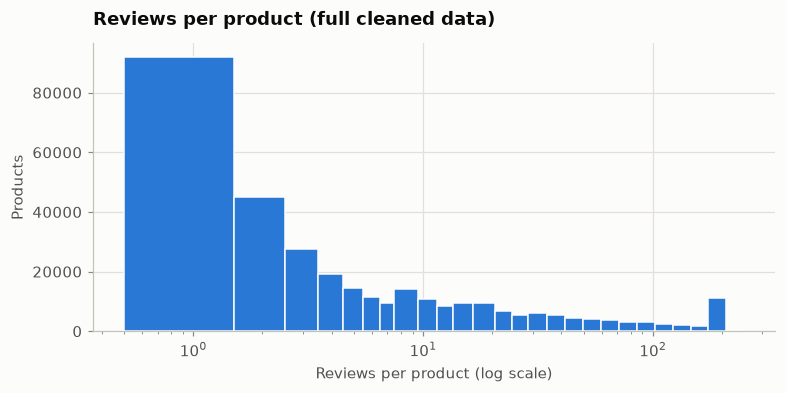

In [32]:
# Bin edges sit between whole numbers, so every count of reviews falls clearly inside one bin
edges = np.unique(np.round(np.logspace(0, np.log10(250), 32))) - 0.5

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(per_product, bins=edges, color=plotting.SERIES[0], edgecolor=plotting.SURFACE)
ax.set_xscale("log")
ax.set_xlabel("Reviews per product (log scale)")
ax.set_ylabel("Products")
ax.set_title("Reviews per product (full cleaned data)")
plotting.save(fig, "reviews_per_product")
plt.show()

### 5.2 Missing values (A2)

Covered in sections 2.2, 2.3 and 4.7. In short: the review body is almost never missing (845 reviews), the
missing seller is fully explained by non-buyers, and missing recommendation labels follow a clear pattern
(non-buyers, early years, less popular products), so they are not missing at random.

### 5.3 Target distributions (A3)

In [33]:
def class_table(values, order):
    table = values.fillna("missing").value_counts().reindex(order).to_frame("reviews")
    table["pct"] = 100 * table["reviews"] / len(values)
    return table


recommendation_table = class_table(
    data["recommendation"], ["recommended", "no_idea", "not_recommended", "missing"]
)
band_table = class_table(data["rating_band"], ["low", "medium", "high", "missing"])
display(recommendation_table, band_table)

,reviews,pct
recommendation,,
recommended,4160043,67.62
no_idea,593625,9.65
not_recommended,504444,8.20
missing,893858,14.53


,reviews,pct
rating_band,,
low,562713,9.15
medium,1058360,17.20
high,4001982,65.05
missing,528915,8.60


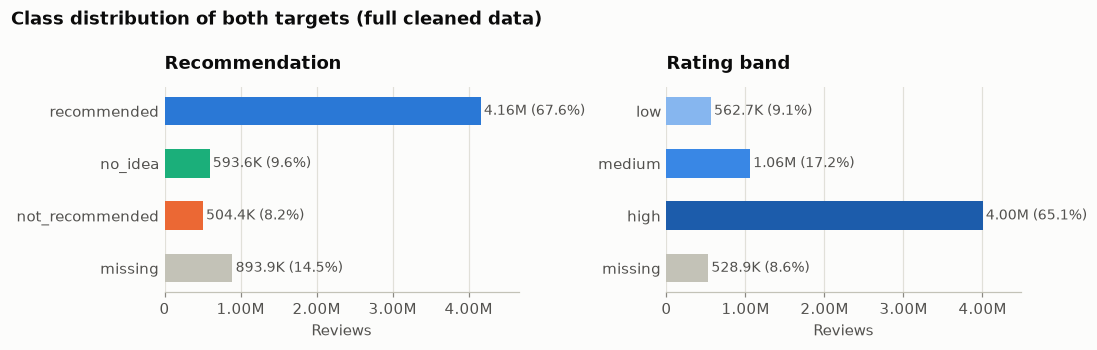

In [34]:
band_colors = {**plotting.RATING_BAND_COLORS, "missing": plotting.NEUTRAL}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, table, colors, title in [
    (axes[0], recommendation_table, plotting.RECOMMENDATION_COLORS, "Recommendation"),
    (axes[1], band_table, band_colors, "Rating band"),
]:
    plotting.hbar(
        ax,
        labels=list(table.index),
        values=list(table["reviews"]),
        colors=[colors[c] for c in table.index],
        value_labels=[
            f"{plotting.compact(n)} ({p:.1f}%)" for n, p in zip(table["reviews"], table["pct"], strict=True)
        ],
        xlabel="Reviews",
    )
    ax.set_title(title)
    ax.xaxis.set_major_formatter(lambda v, _: plotting.compact(v))
fig.suptitle("Class distribution of both targets (full cleaned data)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plotting.save(fig, "target_distributions")
plt.show()

In [35]:
rate = data["rate"][data["rate"] <= 5]
rate_stats = pd.DataFrame(
    {
        "all valid ratings": rate.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]),
        "without zeros": rate[rate > 0].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]),
    }
)
rate_stats.loc["distinct values"] = [rate.nunique(), rate[rate > 0].nunique()]
rate_stats.loc["fractional (%)"] = [100 * (rate % 1 != 0).mean(), 100 * (rate[rate > 0] % 1 != 0).mean()]
rate_stats

,all valid ratings,without zeros
count,"6,151,969.00","5,623,055.00"
mean,3.65,3.99
std,1.57,1.15
min,0.00,0.05
5%,0.00,1.00
25%,3.00,3.00
50%,4.00,4.00
75%,5.00,5.00
95%,5.00,5.00
max,5.00,5.00


Both targets are imbalanced. Among labeled reviews, `recommended` outnumbers `not_recommended` about 8 to 1,
and `high` makes up two thirds of all reviews. This is why Macro F1 and per-class metrics are the main metrics,
and why class weights are considered during training.

The raw `rate` is only used to build `rating_band`. It is never a model input: it is the source of one target,
so feeding it to the model would hand over the answer, and the protocol allows only the review text as input.

### 5.4 Review length (A4)

In [36]:
data["chars"] = data["body"].str.len()
data["words"] = data["body"].str.count(r"\S+")

data[["chars", "words"]].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).T

,count,mean,std,min,50%,75%,90%,95%,99%,max
chars,"6,151,970.00",48.38,64.28,1.00,29.00,57.00,106.00,152.00,296.00,"4,000.00"
words,"6,151,970.00",10.08,13.35,1.00,6.00,12.00,22.00,32.00,62.00,908.00


In [37]:
length_groups = pd.Series(
    {
        "1-2 words": (data["words"] <= 2).sum(),
        "3-10 words": data["words"].between(3, 10).sum(),
        "11-50 words": data["words"].between(11, 50).sum(),
        "51-200 words": data["words"].between(51, 200).sum(),
        "more than 200 words": (data["words"] > 200).sum(),
    },
    name="reviews",
).to_frame()
length_groups["pct"] = 100 * length_groups["reviews"] / len(data)
length_groups

,reviews,pct
1-2 words,1021847,16.61
3-10 words,3347775,54.42
11-50 words,1678056,27.28
51-200 words,102472,1.67
more than 200 words,1820,0.03


In [38]:
percentiles = [0.5, 0.9, 0.95, 0.99]
words_by_label = data.groupby(data["recommendation"].fillna("missing"))["words"].describe(
    percentiles=percentiles
)
words_by_band = data.groupby(data["rating_band"].fillna("missing"))["words"].describe(percentiles=percentiles)
display(words_by_label.loc[LABELS], words_by_band.loc[["low", "medium", "high", "missing"]])

,count,mean,std,min,50%,90%,95%,99%,max
recommendation,,,,,,,,,
recommended,"4,160,043.00",9.23,12.08,1.00,6.00,20.00,28.00,56.00,908.00
no_idea,"593,625.00",12.36,14.90,1.00,8.00,27.00,38.00,70.00,696.00
not_recommended,"504,444.00",15.16,16.71,1.00,10.00,33.00,45.00,79.00,623.00
missing,"893,858.00",9.68,14.85,1.00,5.00,22.00,32.00,67.00,853.00


,count,mean,std,min,50%,90%,95%,99%,max
rating_band,,,,,,,,,
low,"562,713.00",14.08,16.26,1.00,9.00,31.00,43.00,77.00,824.00
medium,"1,058,360.00",11.11,14.48,1.00,7.00,24.00,35.00,68.00,853.00
high,"4,001,982.00",9.14,12.47,1.00,5.00,20.00,28.00,57.00,908.00
missing,"528,915.00",10.89,13.03,1.00,7.00,24.00,33.00,61.00,625.00


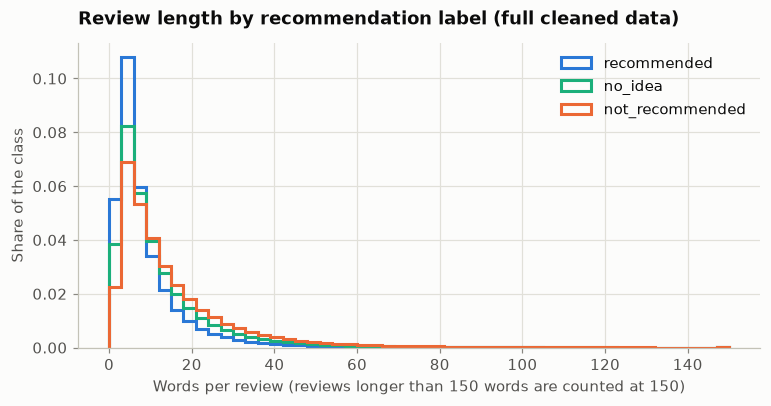

In [39]:
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = range(0, 151, 3)
for label in ["recommended", "no_idea", "not_recommended"]:
    words = data.loc[data["recommendation"] == label, "words"].clip(upper=150)
    ax.hist(
        words,
        bins=bins,
        density=True,
        histtype="step",
        linewidth=2,
        color=plotting.RECOMMENDATION_COLORS[label],
        label=label,
    )
ax.set_xlabel("Words per review (reviews longer than 150 words are counted at 150)")
ax.set_ylabel("Share of the class")
ax.legend(loc="upper right")
ax.set_title("Review length by recommendation label (full cleaned data)")
plotting.save(fig, "length_by_label")
plt.show()

### 5.5 Repeated texts and product concentration (A5)

Duplicate ids were handled in section 2.5. Here the question is about the **text**: how often the exact same
review text appears, whether identical texts carry different labels, and whether the same text shows up on
different products. The last point matters for the split: if a short text like "عالی" appears in both the
training and the test products, the test score partly measures memorization.

Texts are compared after stripping surrounding whitespace, using a hash of each text instead of the text itself
to save memory.

In [40]:
data["text_key"] = pd.util.hash_pandas_object(data["body"].str.strip(), index=False)

text_counts = data["text_key"].value_counts()
repeated = data["text_key"].map(text_counts) > 1
pd.Series(
    {
        "distinct texts": len(text_counts),
        "texts that appear more than once": (text_counts > 1).sum(),
        "reviews whose text appears elsewhere": repeated.sum(),
        "share of reviews (%)": round(100 * repeated.mean(), 2),
    },
    name="value",
).to_frame()

,value
distinct texts,"4,054,477.00"
texts that appear more than once,"190,077.00"
reviews whose text appears elsewhere,"2,287,570.00"
share of reviews (%),37.18


In [41]:
# The 15 most frequent texts
top_keys = text_counts.head(15)
top_texts = data.loc[data["text_key"].isin(top_keys.index)].drop_duplicates("text_key").set_index("text_key")
top_products = data.loc[data["text_key"].isin(top_keys.index)].groupby("text_key")["product_id"].nunique()
pd.DataFrame(
    {
        "text": top_texts.loc[top_keys.index, "body"].str[:60].values,
        "reviews": top_keys.values,
        "products": top_products.loc[top_keys.index].values,
    }
)

,text,reviews,products
0,عالی,134623,60172
1,خوب بود,89915,47418
2,خوبه,83629,41497
3,خوب,70662,39628
4,عالی بود,30548,23332
5,عالیه,23430,18294
6,خیلی خوب بود,17536,14524
7,پیشنهاد میکنم,15398,13183
8,معمولی \n,15141,12136
9,خیلی خوبه,12443,10657


In [42]:
products_per_text = data.groupby("text_key")["product_id"].nunique()
on_several_products = data["text_key"].map(products_per_text) > 1

labeled = data[data["recommendation"].notna()]
labels_per_text = labeled.groupby("text_key")["recommendation"].nunique()
conflicting = labeled["text_key"].map(labels_per_text) > 1

banded = data[data["rating_band"].notna()]
bands_per_text = banded.groupby("text_key")["rating_band"].nunique()
conflicting_band = banded["text_key"].map(bands_per_text) > 1

pd.Series(
    {
        "reviews whose text appears on 2+ products": on_several_products.sum(),
        "  share of all reviews (%)": round(100 * on_several_products.mean(), 2),
        "labeled reviews whose text has 2+ different labels": conflicting.sum(),
        "  share of labeled reviews (%)": round(100 * conflicting.mean(), 2),
        "banded reviews whose text has 2+ different bands": conflicting_band.sum(),
        "  share of banded reviews (%)": round(100 * conflicting_band.mean(), 2),
    },
    name="value",
).to_frame()

,value
reviews whose text appears on 2+ products,"2,286,559.00"
share of all reviews (%),37.17
labeled reviews whose text has 2+ different labels,"1,309,121.00"
share of labeled reviews (%),24.90
banded reviews whose text has 2+ different bands,"1,728,191.00"
share of banded reviews (%),30.73


In [43]:
sorted_counts = per_product.sort_values(ascending=False).to_numpy()
cumulative_reviews = 100 * sorted_counts.cumsum() / sorted_counts.sum()
share_of_products = 100 * np.arange(1, len(sorted_counts) + 1) / len(sorted_counts)


def top_share(pct):
    n = int(len(sorted_counts) * pct / 100)
    return round(100 * sorted_counts[:n].sum() / sorted_counts.sum(), 1)


pd.Series(
    {f"top {p}% of products": top_share(p) for p in [1, 5, 10, 20, 50]},
    name="share of reviews (%)",
).to_frame()

,share of reviews (%)
top 1% of products,10.80
top 5% of products,48.10
top 10% of products,67.10
top 20% of products,82.40
top 50% of products,95.60


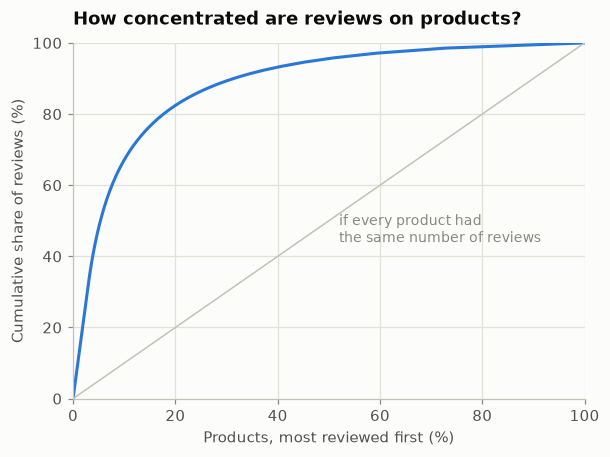

In [44]:
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot(share_of_products, cumulative_reviews, color=plotting.SERIES[0])
ax.plot([0, 100], [0, 100], color=plotting.NEUTRAL, linewidth=1)
ax.text(52, 44, "if every product had\nthe same number of reviews", color=plotting.MUTED, fontsize=9)
ax.set_xlabel("Products, most reviewed first (%)")
ax.set_ylabel("Cumulative share of reviews (%)")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_title("How concentrated are reviews on products?")
plotting.save(fig, "product_concentration")
plt.show()

### 5.6 Findings

**Reviews were collected with a cap of about 200 per product.** 8,346 products have exactly 200 reviews, against
roughly 85 for each count between 190 and 199, and only 23 products have more than 210. The product with 400 raw
rows has just 200 distinct review ids: it was collected twice, and cleaning removed the copies. So the review
counts of popular products are cut off, and "number of reviews" understates how popular the top products are.

**Reviews are concentrated on few products.** Half of the products have 4 reviews or fewer, while the top 10% of
products hold 67% of all reviews. With a random row-level split, reviews of the same popular product would land
in both train and test, and the model could pick up product-specific words (brand, model, size) instead of
opinion. **This is the reason for splitting by product.**

**Both targets are imbalanced.** `recommended` is 67.6% of all reviews (about 8 times `not_recommended`), and
`high` is 65.1%. After the zero-rating decision, `low` is the smallest class at 9.2%. Macro F1, per-class metrics
and class weights follow from this.

**Removing the zeros fixes the rating distribution.** With zeros, the mean rating is 3.65 (std 1.57); without
them it is 3.99 (std 1.15). The zeros were pulling the distribution down artificially.

**Reviews are short.** The median review has 6 words (29 characters); 95% have at most 32 words and 99% at most
62. One review in six (16.6%) is just one or two words, such as `عالی` or `خوب بود`. A short `max_length` will
cover almost every review, which makes Transformer training much cheaper. The exact value is chosen in the
fine-tuning notebook, from token counts measured with the chosen tokenizer.

**Unhappy reviewers write more.** The median `not_recommended` review has 10 words, against 6 for `recommended`;
`low` reviews are also longer than `high` ones. Length carries some signal, which the error analysis should keep
in mind (short negative reviews may be harder).

**Many texts repeat, across products and with different labels.**

- 37% of reviews have a text that appears somewhere else; `عالی` alone appears 134,623 times on 60,172 products.
- 25% of labeled reviews have a text that also appears with a different label, and 31% of reviews with a band
  share their text with a different band. A text like `عالی` is sometimes `recommended` and sometimes `no_idea`.

Two consequences. First, part of the data is ambiguous by nature, so no model can be right on all of it; this
sets a ceiling on achievable scores, especially for very short reviews. Second, identical texts will appear on
both sides of any product split. The split notebook decides how to handle this; the current plan is to keep the
test set as it is and also report scores on the test reviews whose text never appears in training.

**How these findings feed the next steps**

| Finding | Decision it supports |
|---|---|
| Reviews concentrated on few products, product-specific vocabulary | Split by product (70/15/15), never by row |
| Imbalanced targets, `low` only 9.2% | Macro F1 and per-class metrics; class weights; stratify the split on both targets |
| Zero means "no rating recorded" | Zeros get no rating band but stay for the recommendation task |
| Missing labels are structural | Main semi-supervised experiment uses the random protocol mask |
| Short reviews (95% within 32 words) | Short `max_length`, set from token counts in the fine-tuning notebook |
| Identical texts across products and labels | Report scores on unseen texts as well; expect a ceiling on short texts |
| Invisible characters and `\r\n` line breaks inside texts | A normalization step before any model (next stage) |